# Step 1: Imports and Load

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

df = pd.read_csv("customer_churn_dataset-training-master.csv")
df.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,4.0,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0
3,5.0,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1.0
4,6.0,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1.0


In [2]:
print("Shape: ", df.shape)
print()
df.info()

Shape:  (440833, 12)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440833 entries, 0 to 440832
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   CustomerID         440832 non-null  float64
 1   Age                440832 non-null  float64
 2   Gender             440832 non-null  object 
 3   Tenure             440832 non-null  float64
 4   Usage Frequency    440832 non-null  float64
 5   Support Calls      440832 non-null  float64
 6   Payment Delay      440832 non-null  float64
 7   Subscription Type  440832 non-null  object 
 8   Contract Length    440832 non-null  object 
 9   Total Spend        440832 non-null  float64
 10  Last Interaction   440832 non-null  float64
 11  Churn              440832 non-null  float64
dtypes: float64(9), object(3)
memory usage: 40.4+ MB


In [3]:
# Missing Values
df.isnull().sum()

CustomerID           1
Age                  1
Gender               1
Tenure               1
Usage Frequency      1
Support Calls        1
Payment Delay        1
Subscription Type    1
Contract Length      1
Total Spend          1
Last Interaction     1
Churn                1
dtype: int64

In [4]:
# Duplicates
print("Duplicate rows:", df.duplicated().sum())

# Duplicate IDs
print("Duplicate CustomerIDs:", df["CustomerID"].duplicated().sum())

Duplicate rows: 0
Duplicate CustomerIDs: 0


In [5]:
# Target Distribution
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize = True))

Churn
1.0    249999
0.0    190833
Name: count, dtype: int64
Churn
1.0    0.567107
0.0    0.432893
Name: proportion, dtype: float64


In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
CustomerID,440832.0,225398.667955,129531.918550,2.0,113621.75,226125.5,337739.25,449999.0
Age,440832.0,39.373153,12.442369,18.0,29.00,39.0,48.00,65.0
Tenure,440832.0,31.256336,17.255727,1.0,16.00,32.0,46.00,60.0
Usage Frequency,440832.0,15.807494,8.586242,1.0,9.00,16.0,23.00,30.0
Support Calls,440832.0,3.604437,3.070218,0.0,1.00,3.0,6.00,10.0
Payment Delay,440832.0,12.965722,8.258063,0.0,6.00,12.0,19.00,30.0
Total Spend,440832.0,631.616223,240.803001,100.0,480.00,661.0,830.00,1000.0
Last Interaction,440832.0,14.480868,8.596208,1.0,7.00,14.0,22.00,30.0
Churn,440832.0,0.567107,0.495477,0.0,0.00,1.0,1.00,1.0


# Step 2: Cleaning and sanity checks

In [7]:
# Drop the fully empty row and fix dtypes
df = df.dropna(how="all").reset_index(drop=True)
df["CustomerID"] = df["CustomerID"].astype(int)
df["Churn"] = df["Churn"].astype(int)
df["Age"] = df["Age"].astype(int)
print(df.shape, df.isnull().sum().sum())

(440832, 12) 0


In [8]:
# Categorical values
for col in ["Gender", "Subscription Type", "Contract Length"]:
    print(df[col].value_counts(), "\n")

Gender
Male      250252
Female    190580
Name: count, dtype: int64 

Subscription Type
Standard    149128
Premium     148678
Basic       143026
Name: count, dtype: int64 

Contract Length
Annual       177198
Quarterly    176530
Monthly       87104
Name: count, dtype: int64 



In [9]:
# Churn rate by category: which groups churn more?
for col in ["Gender", "Subscription Type", "Contract Length"]:
    print(df.groupby(col)["Churn"].mean().round(3), "\n")

Gender
Female    0.667
Male      0.491
Name: Churn, dtype: float64 

Subscription Type
Basic       0.582
Premium     0.559
Standard    0.561
Name: Churn, dtype: float64 

Contract Length
Annual       0.461
Monthly      1.000
Quarterly    0.460
Name: Churn, dtype: float64 



In [10]:
# Churn rate by numeric feature (mean per class)
df.groupby("Churn")[["Age", "Tenure", "Usage Frequency", "Support Calls", 
                     "Payment Delay", "Total Spend", "Last Interaction"]].mean().round(2)

,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction
Churn,,,,,,,
0,36.26,32.28,16.26,1.59,10.02,749.95,13.01
1,41.75,30.47,15.46,5.14,15.22,541.29,15.60


    Every Monthly-contract customer churned (100.0%). That’s not a real-world pattern. It’s an artifact of how the synthetic data was generated.
    Why it matters?
    A model will learn “Monthly means churn” and score near-perfect on those 87k rows, which inflates our Area Under teh Curve (AUC).
    Gender (66.7% vs 49.1%) is probably confounded with contract type. we will check this out before drawing conclusions from it.

# Step 3: Confirm the artifact

In [11]:
# Is Monthly really 100%? Any non-churners at all?
print(df[df["Contract Length"] == "Monthly"]["Churn"].value_counts())

Churn
1    87104
Name: count, dtype: int64


In [12]:
# Is the gender gap explianed by contract type?
print(pd.crosstab(df["Gender"], df["Contract Length"], normalize="index").round(3))

Contract Length  Annual  Monthly  Quarterly
Gender                                     
Female            0.385    0.228      0.386
Male              0.415    0.174      0.411


In [13]:
# Churn rate by contract within the remaining data
df_main = df[df["Contract Length"] != "Monthly"].copy()
print(df_main.shape)
print(df_main["Churn"].value_counts(normalize=True).round(3))
print(df_main.groupby("Gender")["Churn"].mean().round(3))
print(df_main.groupby("Subscription Type")["Churn"].mean().round(3))

(353728, 12)
Churn
0    0.539
1    0.461
Name: proportion, dtype: float64
Gender
Female    0.568
Male      0.384
Name: Churn, dtype: float64
Subscription Type
Basic       0.475
Premium     0.452
Standard    0.455
Name: Churn, dtype: float64


In [14]:
# Do the numeric features still separate churners in the filtered data?
df_main.groupby("Churn")[["Age", "Tenure", "Usage Frequency", "Support Calls", 
                          "Payment Delay", "Total Spend", "Last Interaction"]].mean().round(2)

,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction
Churn,,,,,,,
0,36.26,32.28,16.26,1.59,10.02,749.95,13.01
1,41.85,30.44,15.44,5.23,15.33,536.30,15.67


    Monthly is exactly 100% churn (87,104 of 87,104). It’s a hard synthetic rule, so we exclude it and we're left with 353,728 rows with a healthier 46.1% churn rate.
    Contract mix explains part of it (females are more often on Monthly), but within the filtered data it’s still 56.8% vs 38.4%. So it’s a built-in effect of the data generator. We’ll drop Gender from the model anyway, because using gender to decide who gets a retention offer is a fairness problem.
    Subscription Type barely matters (45-47.5%), and Annual vs Quarterly are nearly identical (46.1% vs 46.0%), so contract length carries almost no signal now.
    The real signals are Support Calls (1.6 vs 5.2), Payment Delay (10 vs 15), Total Spend (750 vs 536) and Age.

# Step 4: EDA plots, features and splits

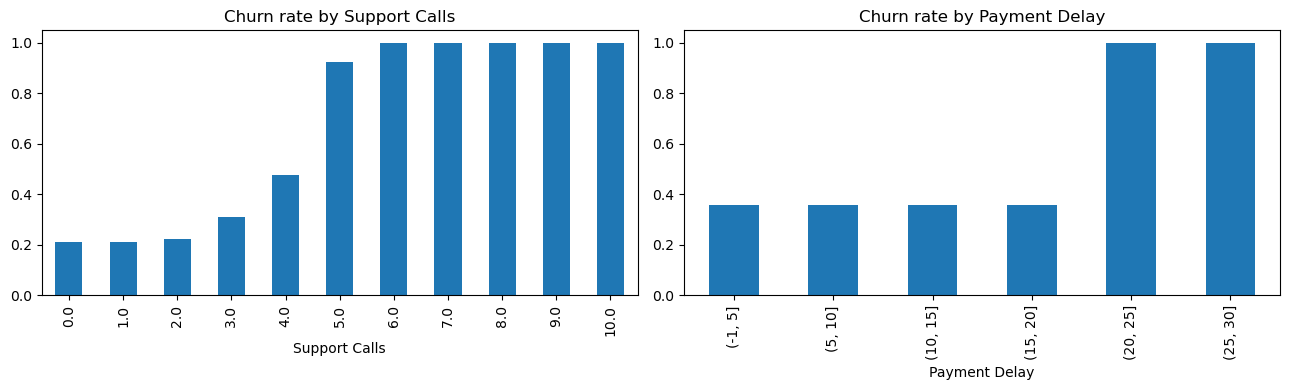

In [15]:
# 1. Churn rate by support calls and by payment-delay bucket
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
df_main.groupby("Support Calls")["Churn"].mean().plot(kind="bar", ax=ax[0], title="Churn rate by Support Calls")
df_main.groupby(pd.cut(df_main["Payment Delay"], [-1, 5, 10, 15, 20, 25, 30]), observed=True)["Churn"].mean().plot(
    kind="bar", ax=ax[1], title="Churn rate by Payment Delay")
plt.tight_layout()
plt.show()

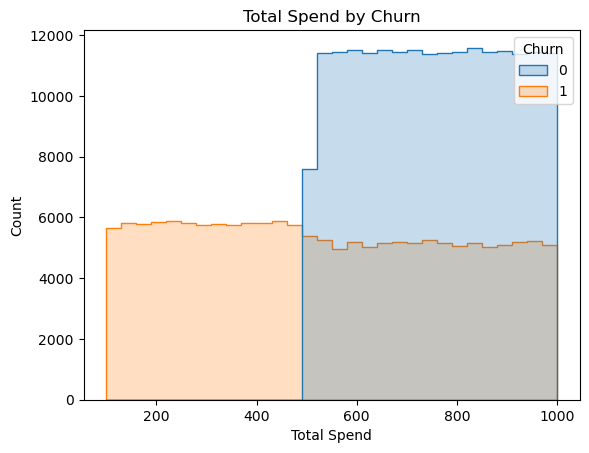

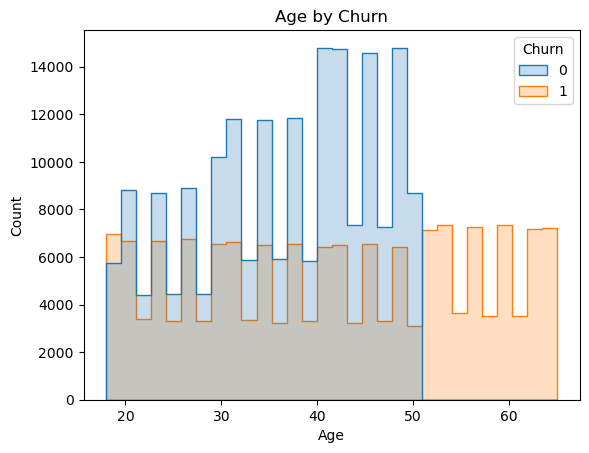

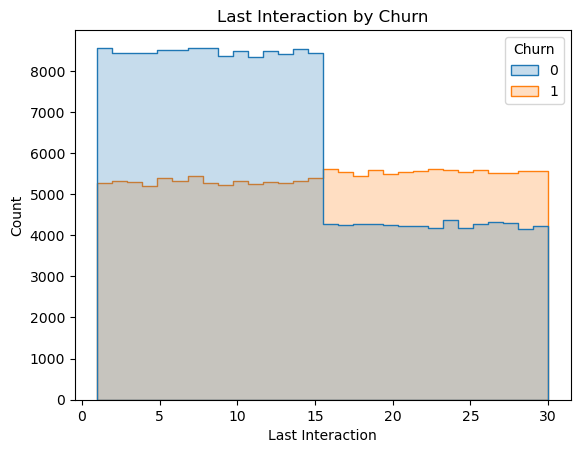

In [16]:
# 2. Distributions by churn class
for col in ["Total Spend", "Age", "Last Interaction"]:
    sns.histplot(data=df_main, x=col, hue="Churn", bins=30, element="step")
    plt.title(f"{col} by Churn")
    plt.show()

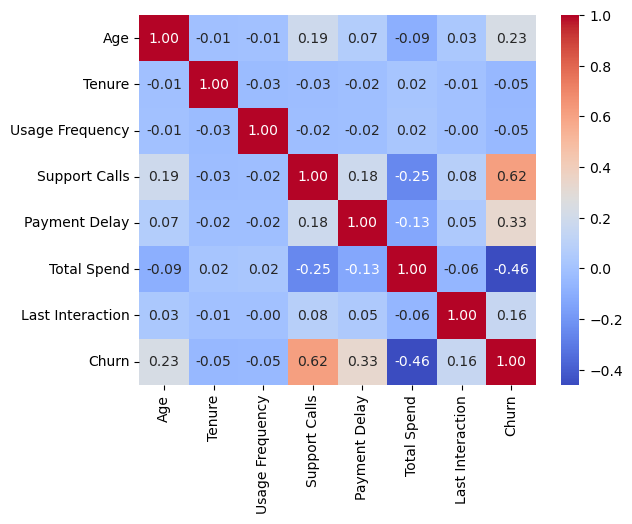

In [17]:
# 3. Correlation heatmap
num_cols = ["Age", "Tenure", "Usage Frequency", "Support Calls", "Payment Delay", 
            "Total Spend", "Last Interaction", "Churn"]
sns.heatmap(df_main[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

In [18]:
# 4. Build the modelling dataset: drop ID and Gender, one-hot the categoricals
X = df_main.drop(columns=["CustomerID", "Gender", "Churn"])
X = pd.get_dummies(X, columns=["Subscription Type", "Contract Length"], drop_first=True)
y = df_main["Churn"]
print(X.shape)
X.head()

(353728, 10)


,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Subscription Type_Premium,Subscription Type_Standard,Contract Length_Quarterly
0,30,39.0,14.0,5.0,18.0,932.0,17.0,False,True,False
2,55,14.0,4.0,6.0,18.0,185.0,3.0,False,False,True
5,51,33.0,25.0,9.0,26.0,129.0,8.0,True,False,False
6,58,49.0,12.0,3.0,16.0,821.0,24.0,False,True,True
7,55,37.0,8.0,4.0,15.0,445.0,30.0,True,False,False


In [19]:
# 5. Stratified train/validation split
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_val.shape)
print(y_train.mean().round(3), y_val.mean().round(3))

(282982, 10) (70746, 10)
0.461 0.461


# Step 5: Baselines and models

### 1. Metrics helper

In [20]:
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score, confusion_matrix

def evaluate(name, model, X_val, y_val):
    proba = model.predict_proba(X_val)[:, 1]
    pred = (proba >= 0.5).astype(int)
    print(f"=== {name} ===")
    print("ROC-AUC:", round(roc_auc_score(y_val, proba), 4))
    print("PR-AUC :", round(average_precision_score(y_val, proba), 4))
    print(confusion_matrix(y_val, pred))
    print(classification_report(y_val, pred, digits=3))
    return proba

### 2. Logistic regression baseline

In [21]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
lr.fit(X_train, y_train)
p_lr = evaluate("Logistic Regression", lr, X_val, y_val)

=== Logistic Regression ===
ROC-AUC: 0.9314
PR-AUC : 0.9378
[[34298  3869]
 [ 5912 26667]]
              precision    recall  f1-score   support

           0      0.853     0.899     0.875     38167
           1      0.873     0.819     0.845     32579

    accuracy                          0.862     70746
   macro avg      0.863     0.859     0.860     70746
weighted avg      0.862     0.862     0.861     70746



### 3. Shallow decision tree: this exposes the hidden rules

In [22]:
from sklearn.tree import DecisionTreeClassifier, export_text

dt = DecisionTreeClassifier(max_depth=4, random_state=42)
dt.fit(X_train, y_train)
p_dt = evaluate("Decision Tree (depth 4)", dt, X_val, y_val)
print(export_text(dt, feature_names=list(X.columns)))

=== Decision Tree (depth 4) ===
ROC-AUC: 0.9704
PR-AUC : 0.9683
[[38164     3]
 [ 1974 30605]]
              precision    recall  f1-score   support

           0      0.951     1.000     0.975     38167
           1      1.000     0.939     0.969     32579

    accuracy                          0.972     70746
   macro avg      0.975     0.970     0.972     70746
weighted avg      0.973     0.972     0.972     70746

|--- Support Calls <= 4.50
|   |--- Total Spend <= 500.01
|   |   |--- Total Spend <= 499.93
|   |   |   |--- class: 1
|   |   |--- Total Spend >  499.93
|   |   |   |--- Payment Delay <= 1.50
|   |   |   |   |--- class: 0
|   |   |   |--- Payment Delay >  1.50
|   |   |   |   |--- class: 1
|   |--- Total Spend >  500.01
|   |   |--- Payment Delay <= 20.50
|   |   |   |--- Age <= 50.50
|   |   |   |   |--- class: 0
|   |   |   |--- Age >  50.50
|   |   |   |   |--- class: 1
|   |   |--- Payment Delay >  20.50
|   |   |   |--- class: 1
|--- Support Calls >  4.50
|   |--- S

### 4. Random Forest

In [23]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
p_rf = evaluate("Random Forest", rf, X_val, y_val)

=== Random Forest ===
ROC-AUC: 0.9961
PR-AUC : 0.9964
[[38164     3]
 [  765 31814]]
              precision    recall  f1-score   support

           0      0.980     1.000     0.990     38167
           1      1.000     0.977     0.988     32579

    accuracy                          0.989     70746
   macro avg      0.990     0.988     0.989     70746
weighted avg      0.989     0.989     0.989     70746



### 5. LightGBM

In [25]:
import lightgbm as lgb

lgbm = lgb.LGBMClassifier(n_estimators=1000, learning_rate=0.05, num_leaves=31, random_state=42)
lgbm.fit(X_train, y_train,
         eval_set=[(X_val, y_val)], eval_metric="auc",
         callbacks=[lgb.early_stopping(50), lgb.log_evaluation(100)])
p_lgb = evaluate("LightGBM", lgbm, X_val, y_val)

C:\Users\soumi\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\soumi\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\soumi\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\soumi\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\soumi\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 130316, number of negative: 152666
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.036829 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 475
[LightGBM] [Info] Number of data points in the train set: 282982, number of used features: 10
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.460510 -> initscore=-0.158290
[LightGBM] [Info] Start training from score -0.158290
Training until validation scores don't improve for 50 rounds
[100]	valid_0's auc: 0.996153	valid_0's binary_logloss: 0.0458871
Early stopping, best iteration is:
[105]	valid_0's auc: 0.996171	valid_0's binary_logloss: 0.0451864
=== LightGBM ===
ROC-AUC: 0.9962
PR-AUC : 0.9964
[[38157    10]
 [  783 31796]]
              precision    recall  f

### 6. Comparison Table

In [26]:
results = pd.DataFrame({
    "model": ["LogReg", "Tree(d4)", "RandomForest", "LightGBM"],
    "ROC-AUC": [roc_auc_score(y_val, p) for p in [p_lr, p_dt, p_rf, p_lgb]],
    "PR-AUC":  [average_precision_score(y_val, p) for p in [p_lr, p_dt, p_rf, p_lgb]],
}).round(4)
results

,model,ROC-AUC,PR-AUC
0,LogReg,0.9314,0.9378
1,Tree(d4),0.9704,0.9683
2,RandomForest,0.9961,0.9964
3,LightGBM,0.9962,0.9964


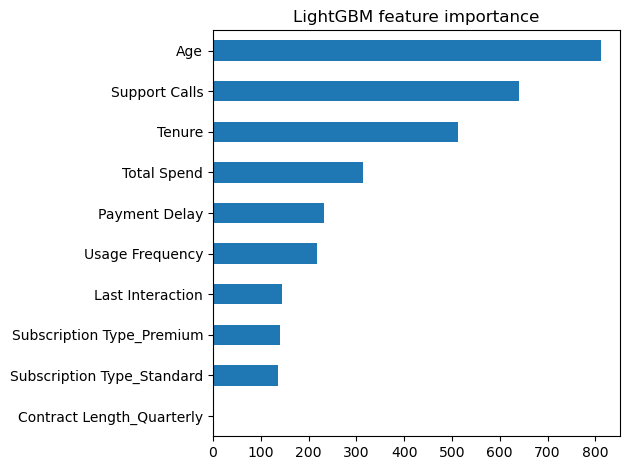

In [27]:
# Feature importance from LightGBM
imp = pd.Series(lgbm.feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", title="LightGBM feature importance")
plt.tight_layout(); plt.show()

### 7. Proper train / validation / test split

In [28]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"   # silences the core-count warning

from sklearn.model_selection import train_test_split

# 60% train / 20% validation / 20% test, all stratified
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42)
print(X_train.shape, X_val.shape, X_test.shape)

(212236, 10) (70746, 10) (70746, 10)


In [29]:
# Retrain LightGBM: early stopping on VALIDATION, final scoring on TEST
lgbm = lgb.LGBMClassifier(n_estimators=1000, learning_rate=0.05, num_leaves=31,
                          random_state=42, verbose=-1)
lgbm.fit(X_train, y_train,
         eval_set=[(X_val, y_val)], eval_metric="auc",
         callbacks=[lgb.early_stopping(50), lgb.log_evaluation(0)])

p_test = evaluate("LightGBM (TEST set)", lgbm, X_test, y_test)

C:\Users\soumi\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[94]	valid_0's auc: 0.996392	valid_0's binary_logloss: 0.0460216
=== LightGBM (TEST set) ===
ROC-AUC: 0.9962
PR-AUC : 0.9963
[[38148    19]
 [  779 31800]]
              precision    recall  f1-score   support

           0      0.980     1.000     0.990     38167
           1      0.999     0.976     0.988     32579

    accuracy                          0.989     70746
   macro avg      0.990     0.988     0.989     70746
weighted avg      0.989     0.989     0.989     70746



### 8. Where does the model fail?

In [30]:
# The missed churners: customers the model was confident would stay but left
test_df = X_test.copy()
test_df["y"] = y_test.values
test_df["p"] = p_test
missed = test_df[(test_df["y"] == 1) & (test_df["p"] < 0.5)]
print(len(missed))
missed[["Age", "Support Calls", "Payment Delay", "Total Spend", "Last Interaction", "Tenure", "Usage Frequency"]].describe().T.round(1)

779


,count,mean,std,min,25%,50%,75%,max
Age,779.0,36.5,9.3,18.0,30.0,38.0,45.0,50.0
Support Calls,779.0,1.7,1.3,0.0,1.0,2.0,3.0,5.0
Payment Delay,779.0,9.9,6.2,0.0,5.0,10.0,15.0,20.0
Total Spend,779.0,747.2,145.7,494.5,621.5,746.4,875.5,1000.0
Last Interaction,779.0,22.6,4.8,1.0,19.0,23.0,26.0,30.0
Tenure,779.0,31.3,16.9,1.0,17.0,32.0,45.0,60.0
Usage Frequency,779.0,16.3,8.6,1.0,9.0,16.0,24.0,30.0


### Step 9: Calibration

Brier (raw): 0.01045
Brier (calibrated): 0.01016


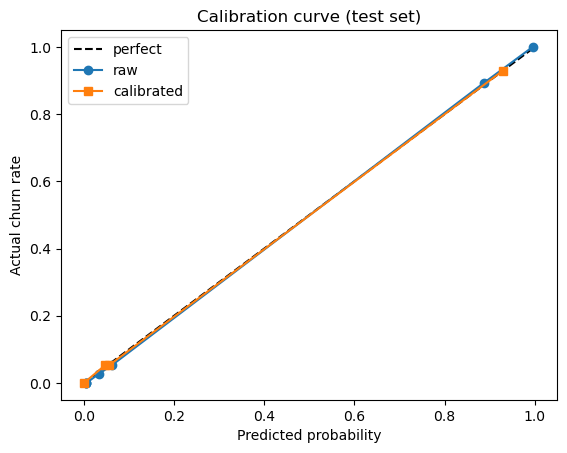

In [31]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
from sklearn.isotonic import IsotonicRegression

# Raw model calibration on TEST
frac_pos, mean_pred = calibration_curve(y_test, p_test, n_bins=10, strategy="quantile")
print("Brier (raw):", round(brier_score_loss(y_test, p_test), 5))

# Fit a calibrator on VALIDATION probabilities, apply to TEST
p_val = lgbm.predict_proba(X_val)[:, 1]
iso = IsotonicRegression(out_of_bounds="clip").fit(p_val, y_val)
p_test_cal = iso.predict(p_test)
print("Brier (calibrated):", round(brier_score_loss(y_test, p_test_cal), 5))

frac_pos_c, mean_pred_c = calibration_curve(y_test, p_test_cal, n_bins=10, strategy="quantile")

plt.plot([0, 1], [0, 1], "k--", label="perfect")
plt.plot(mean_pred, frac_pos, "o-", label="raw")
plt.plot(mean_pred_c, frac_pos_c, "s-", label="calibrated")
plt.xlabel("Predicted probability"); plt.ylabel("Actual churn rate")
plt.legend(); plt.title("Calibration curve (test set)"); plt.show()

### 10. SHAP and saving the model

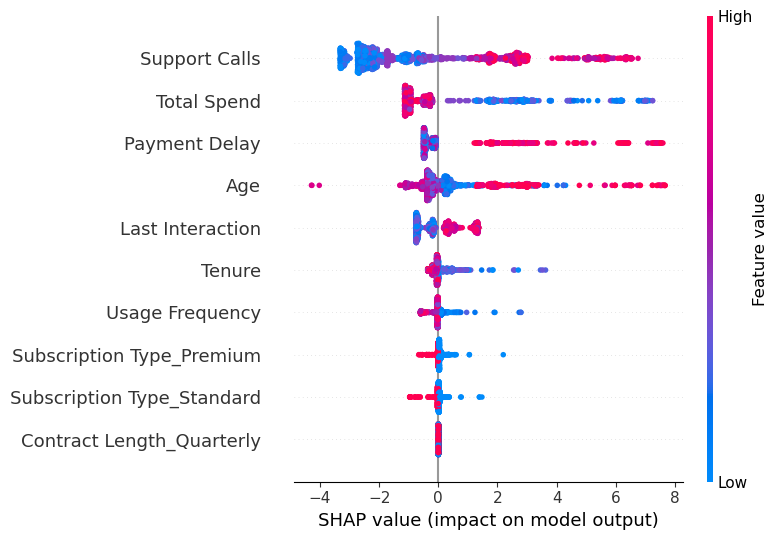

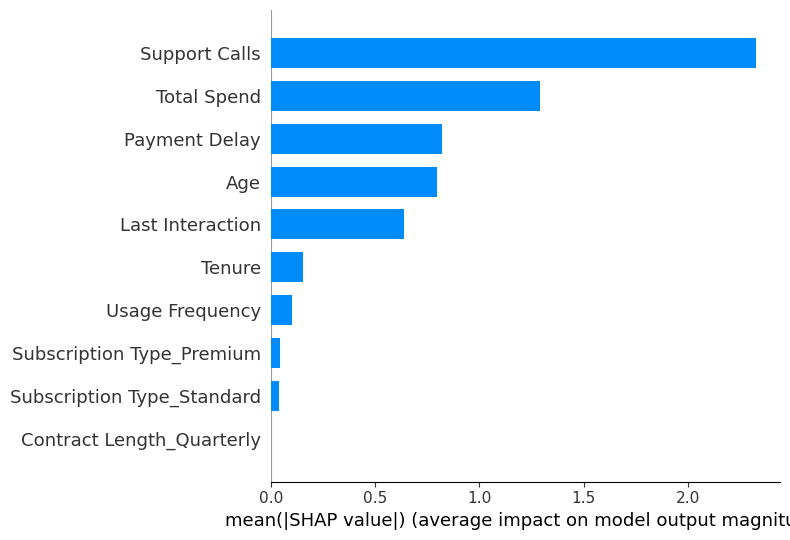

In [34]:
import shap

sample = X_test.sample(2000, random_state=42)
explainer = shap.TreeExplainer(lgbm)
sv = explainer(sample)
vals = sv.values[:, :, 1] if sv.values.ndim == 3 else sv.values   # handles version differences

shap.summary_plot(vals, sample)                 # global: which features matter and how
shap.summary_plot(vals, sample, plot_type="bar")

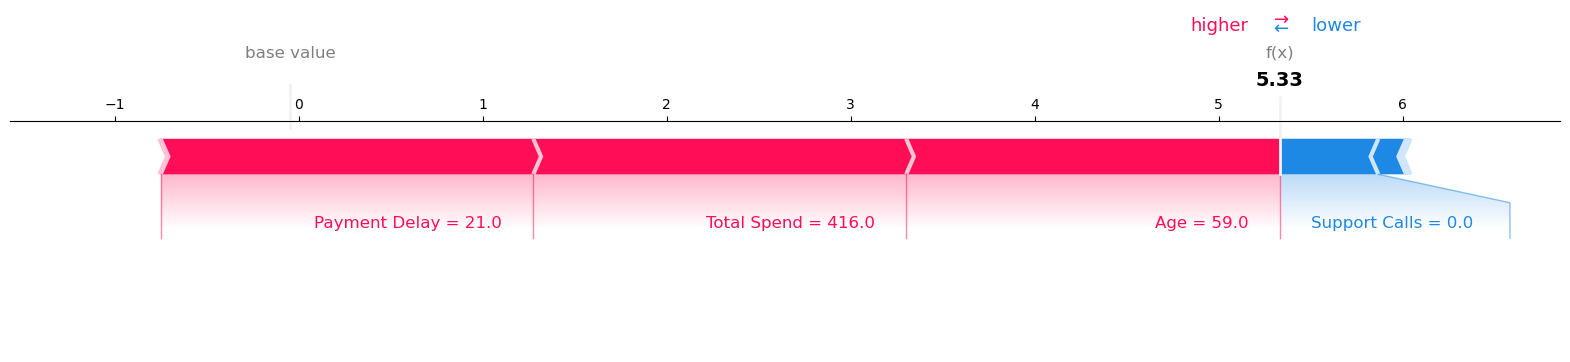

In [35]:
# Explain one specific customer
i = 0
shap.force_plot(explainer.expected_value if np.ndim(explainer.expected_value) == 0 else explainer.expected_value[1],
                vals[i], sample.iloc[i], matplotlib=True)

In [36]:
import os, joblib
os.makedirs("../models", exist_ok=True)
joblib.dump(lgbm, "../models/lgbm_churn.joblib")
joblib.dump(iso, "../models/isotonic_calibrator.joblib")
joblib.dump(list(X.columns), "../models/feature_columns.joblib")

['../models/feature_columns.joblib']

# Step 6: The Offer Engine

In [38]:
# 1. SHAP values for the whole test set, to find each customer's main churn driver
explainer = shap.TreeExplainer(lgbm)
sv = explainer.shap_values(X_test)
if isinstance(sv, list): sv = sv[1]
elif sv.ndim == 3: sv = sv[:, :, 1]
shap_df = pd.DataFrame(sv, columns=X_test.columns, index=X_test.index)

driver_map = {"Support Calls": "service", "Payment Delay": "payment",
              "Total Spend": "pricing", "Last Interaction": "engagement"}
top_driver = shap_df[list(driver_map)].idxmax(axis=1).map(driver_map)
top_driver.value_counts()

C:\Users\soumi\anaconda3\Lib\site-packages\shap\explainers\_tree.py:448: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn('LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray')


payment       29689
service       17982
engagement    14681
pricing        8394
Name: count, dtype: int64

In [39]:
# 2. ASSUMED probability that each offer saves a customer, by churn reason
rates = {
    "payment":    {"discount": 0.25, "review": 0.10, "plan": 0.40},
    "service":    {"discount": 0.20, "review": 0.35, "plan": 0.05},
    "pricing":    {"discount": 0.35, "review": 0.10, "plan": 0.05},
    "engagement": {"discount": 0.15, "review": 0.25, "plan": 0.05},
}
fixed_cost = {"review": 15, "plan": 5}

value = X_test["Total Spend"].values
p = p_test_cal

# 3. Expected value of every offer for every customer
ev = pd.DataFrame({"none": np.zeros(len(p))}, index=X_test.index)
for offer in ["discount", "review", "plan"]:
    r = top_driver.map(lambda d: rates[d][offer]).values
    cost = 0.20 * value if offer == "discount" else fixed_cost[offer]
    ev[offer] = p * r * value - cost

best_offer = ev.idxmax(axis=1)
print(best_offer.value_counts())

none        38866
review      18982
discount     8394
plan         4504
Name: count, dtype: int64


In [40]:
# 4. Compare against baselines (all under the same assumed rates)
engine_profit = ev.max(axis=1).sum()
all_discount = ev["discount"].sum()
top_n = p >= np.quantile(p, 0.80)            # discount only to the top 20% by churn risk
topn_discount = ev.loc[top_n, "discount"].sum()

print(f"Engine (best offer per customer): {engine_profit:,.0f}")
print(f"Discount to everyone            : {all_discount:,.0f}")
print(f"Discount to top 20% by risk     : {topn_discount:,.0f}")

Engine (best offer per customer): 5,195,890
Discount to everyone            : -5,254,462
Discount to top 20% by risk     : 497,670


In [41]:
# 5. One customer's recommendation, with the reason
i = ev.max(axis=1).sort_values(ascending=False).index[0]
print("Customer:", i, "| churn prob:", round(float(p[X_test.index.get_loc(i)]), 3),
      "| main driver:", top_driver[i], "| recommend:", best_offer[i])
ev.loc[i].round(1)

Customer: 30630 | churn prob: 1.0 | main driver: payment | recommend: plan


none          0.0
discount     50.0
review       85.0
plan        395.0
Name: 30630, dtype: float64

In [44]:
# Fairer baselines: one single offer to everyone with p >= 0.5
risky = p >= 0.5
print("Customers targeted by engine:", (best_offer != "none").sum(), "| with p>=0.5:", risky.sum())
print(f"Engine (matched offer)      : {ev.max(axis=1).sum():,.0f}")
for offer in ["discount", "review", "plan"]:
    print(f"{offer:9s} to all p>=0.5  : {ev.loc[risky, offer].sum():,.0f}")

Customers targeted by engine: 31880 | with p>=0.5: 31859
Engine (matched offer)      : 5,195,890
discount  to all p>=0.5  : 498,313
review    to all p>=0.5  : 3,894,660
plan      to all p>=0.5  : 1,860,992


In [45]:
# Robustness: do recommendations survive if the assumed rates are 50% lower / 50% higher?
for scale in [0.5, 1.5]:
    ev_s = pd.DataFrame({"none": np.zeros(len(p))}, index=X_test.index)
    for offer in ["discount", "review", "plan"]:
        r = top_driver.map(lambda d: min(rates[d][offer] * scale, 1.0)).values
        cost = 0.20 * value if offer == "discount" else fixed_cost[offer]
        ev_s[offer] = p * r * value - cost
    changed = (ev_s.idxmax(axis=1) != best_offer).mean()
    print(f"rates x{scale}: {changed:.1%} of recommendations change")

rates x0.5: 11.9% of recommendations change
rates x1.5: 9.3% of recommendations change


In [48]:
reason_text = {
    "payment": "Late payments are the main churn driver",
    "service": "Frequent support calls are the main churn driver",
    "pricing": "Low spend is the main churn driver",
    "engagement": "Long gap since last interaction is the main driver",
}
scored = pd.DataFrame({
    "customer_id": df_main.loc[X_test.index, "CustomerID"].values,
    "churn_prob": p.round(4),
    "main_driver": top_driver.values,
    "reason": top_driver.map(reason_text).values,
    "recommended_offer": best_offer.values,
    "expected_value": ev.max(axis=1).round(1).values,
    "total_spend": value,
})
# For customers with no action, a "driver" is meaningless, so blank it out
no_action = scored["recommended_offer"] == "none"
scored.loc[no_action, "main_driver"] = "-"
scored.loc[no_action, "reason"] = "Low churn risk, no action"

scored = scored.sort_values("expected_value", ascending=False)
scored.to_csv("scored_customers.csv", index=False)
print(scored.shape)
scored.head(10)

(70746, 7)


,customer_id,churn_prob,main_driver,reason,recommended_offer,expected_value,total_spend
47433,1890,1.0,payment,Late payments are the main churn driver,plan,395.0,1000.00
17397,126503,1.0,payment,Late payments are the main churn driver,plan,395.0,1000.00
2053,30639,1.0,payment,Late payments are the main churn driver,plan,395.0,1000.00
54478,10031,1.0,payment,Late payments are the main churn driver,plan,395.0,1000.00
18338,84555,1.0,payment,Late payments are the main churn driver,plan,395.0,1000.00
6947,224309,1.0,payment,Late payments are the main churn driver,plan,394.9,999.72
18318,36718,1.0,payment,Late payments are the main churn driver,plan,394.6,999.00
7340,10575,1.0,payment,Late payments are the main churn driver,plan,394.6,999.00
40394,164833,1.0,payment,Late payments are the main churn driver,plan,394.6,999.00
49212,260414,1.0,payment,Late payments are the main churn driver,plan,394.3,998.26
